<a href="https://colab.research.google.com/github/Aman-k123/python-HCL-project1/blob/main/HCL_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("HCL Project Started Successfully!")

HCL Project Started Successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sample_hotel_bookings.csv to sample_hotel_bookings (1).csv


In [ ]:
df = pd.read_csv('sample_hotel_bookings.csv')

print("Dataset Loaded Successfully!")
print("Total Rows and Columns:", df.shape)

df.head()

Dataset Loaded Successfully!
Total Rows and Columns: (1200, 10)


,hotel,is_canceled,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,market_segment,customer_type,adr,reservation_status
0,Resort Hotel,1,119,July,3,5,Online TA,Transient,129.61,Canceled
1,City Hotel,0,72,July,2,1,Groups,Transient,50.61,Check-Out
2,Resort Hotel,0,25,October,0,7,Direct,Transient,128.84,Check-Out
3,Resort Hotel,0,84,September,0,4,Online TA,Transient-Party,118.40,Check-Out
4,City Hotel,1,169,January,3,1,Online TA,Transient,109.55,Canceled


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hotel                    1200 non-null   object 
 1   is_canceled              1200 non-null   int64  
 2   lead_time                1200 non-null   int64  
 3   arrival_date_month       1200 non-null   object 
 4   stays_in_weekend_nights  1200 non-null   int64  
 5   stays_in_week_nights     1200 non-null   int64  
 6   market_segment           1200 non-null   object 
 7   customer_type            1200 non-null   object 
 8   adr                      1200 non-null   float64
 9   reservation_status       1200 non-null   object 
dtypes: float64(1), int64(4), object(5)
memory usage: 93.9+ KB

Missing Values:
hotel                      0
is_canceled                0
lead_time                  0
arrival_date_month         0
stays_in_weekend_nights    0

In [ ]:
total_bookings = len(df)

cancelled_bookings = df['is_canceled'].sum()

successful_bookings = total_bookings - cancelled_bookings

cancellation_rate = (cancelled_bookings / total_bookings) * 100

print("TOTAL BOOKING ANALYSIS")
print("Total Bookings:", total_bookings)
print("Cancelled Bookings:", cancelled_bookings)
print("Successful Bookings:", successful_bookings)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

TOTAL BOOKING ANALYSIS
Total Bookings: 1200
Cancelled Bookings: 342
Successful Bookings: 858
Cancellation Rate: 28.5 %


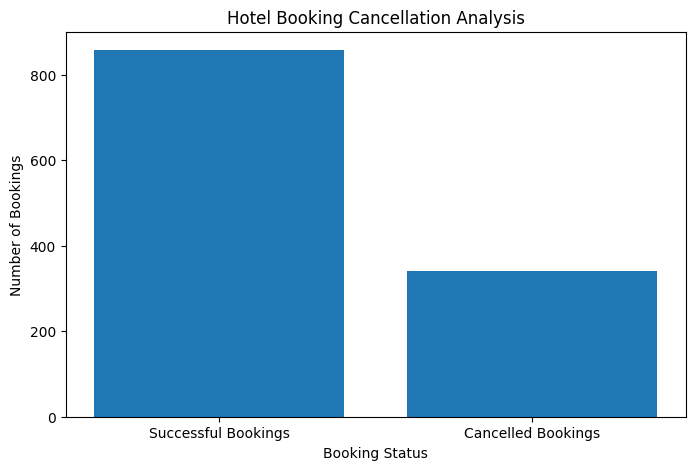

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    ['Successful Bookings', 'Cancelled Bookings'],
    [successful_bookings, cancelled_bookings]
)

plt.title("Hotel Booking Cancellation Analysis")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.show()

Monthly Booking Details:
arrival_date_month
January       58
February      68
March         75
April        105
May          124
June         140
July         152
August       116
September    103
October       97
November      83
December      79
Name: count, dtype: int64


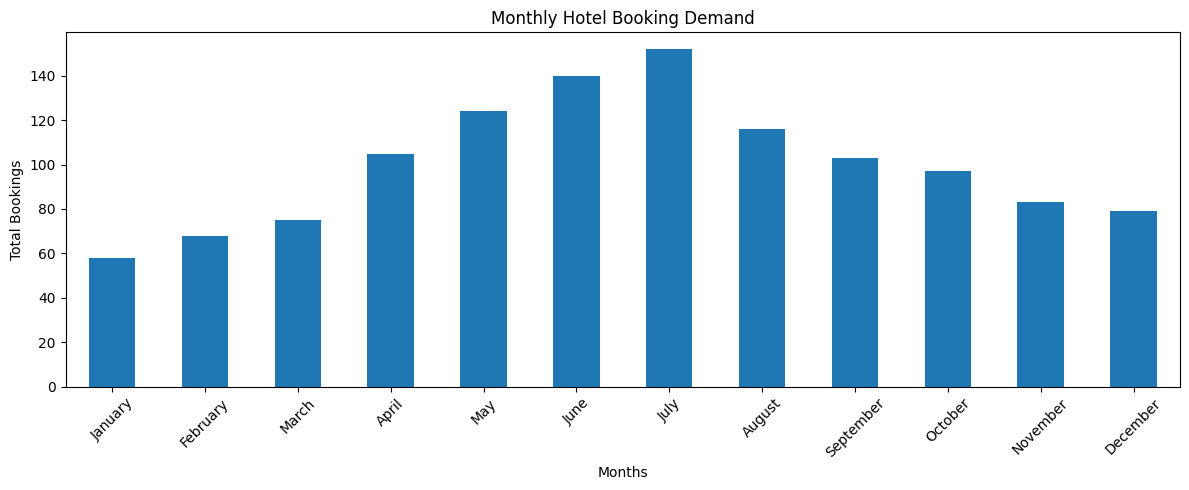

In [ ]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = df['arrival_date_month'].value_counts()

monthly_bookings = monthly_bookings.reindex(month_order).fillna(0)

print("Monthly Booking Details:")
print(monthly_bookings)

plt.figure(figsize=(12,5))

monthly_bookings.plot(kind='bar')

plt.title("Monthly Hotel Booking Demand")
plt.xlabel("Months")
plt.ylabel("Total Bookings")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Hotel Booking Comparison:
hotel
City Hotel      735
Resort Hotel    465
Name: count, dtype: int64


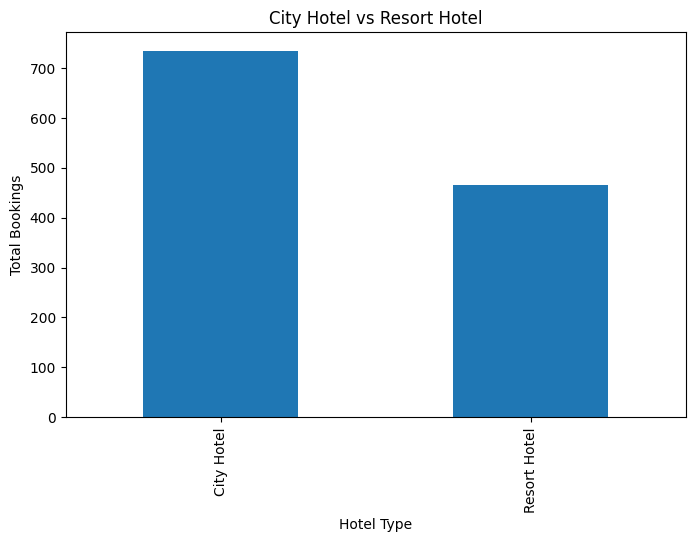

In [ ]:
hotel_bookings = df['hotel'].value_counts()

print("Hotel Booking Comparison:")
print(hotel_bookings)

plt.figure(figsize=(8,5))

hotel_bookings.plot(kind='bar')

plt.title("City Hotel vs Resort Hotel")
plt.xlabel("Hotel Type")
plt.ylabel("Total Bookings")

plt.show()

Booking Market Segment Details:
market_segment
Online TA     594
Direct        268
Groups        163
Corporate     101
Offline TA     74
Name: count, dtype: int64


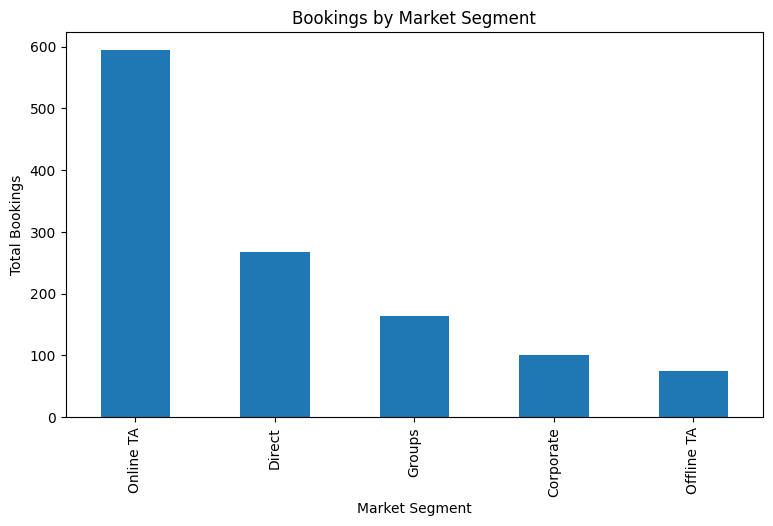

In [ ]:
segment_bookings = df['market_segment'].value_counts()

print("Booking Market Segment Details:")
print(segment_bookings)

plt.figure(figsize=(9,5))

segment_bookings.plot(kind='bar')

plt.title("Bookings by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Total Bookings")

plt.show()

Customer Type Details:
customer_type
Transient          828
Transient-Party    265
Contract            71
Group               36
Name: count, dtype: int64


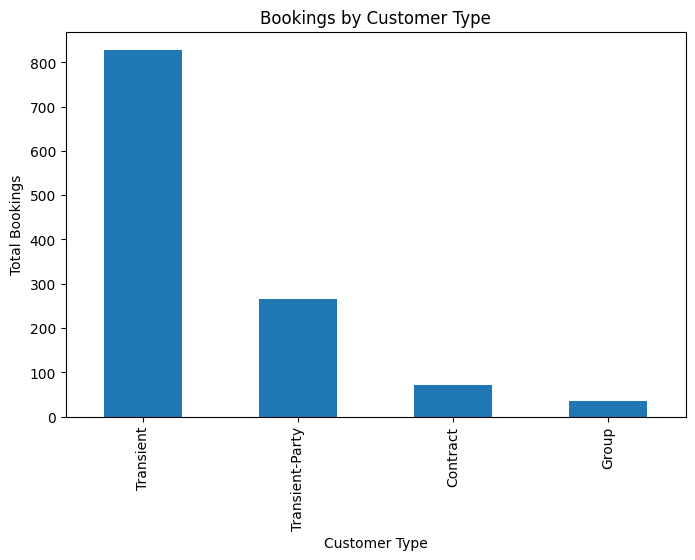

In [ ]:
customer_bookings = df['customer_type'].value_counts()

print("Customer Type Details:")
print(customer_bookings)

plt.figure(figsize=(8,5))

customer_bookings.plot(kind='bar')

plt.title("Bookings by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Bookings")

plt.show()

Average Length of Stay: 5.55 nights


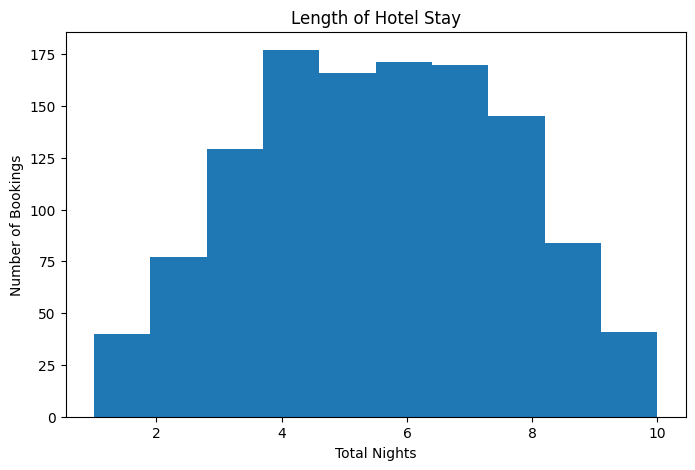

In [ ]:
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

print("Average Length of Stay:",
      round(df['total_nights'].mean(), 2), "nights")

plt.figure(figsize=(8,5))

df['total_nights'].plot(kind='hist', bins=10)

plt.title("Length of Hotel Stay")
plt.xlabel("Total Nights")
plt.ylabel("Number of Bookings")

plt.show()

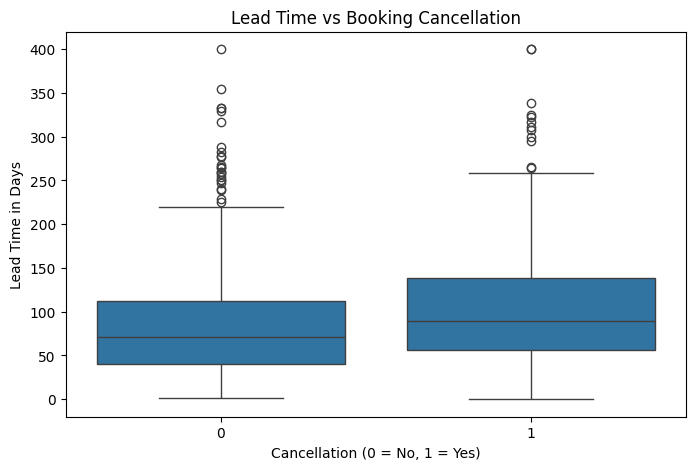

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='is_canceled',
    y='lead_time',
    data=df
)

plt.title("Lead Time vs Booking Cancellation")
plt.xlabel("Cancellation (0 = No, 1 = Yes)")
plt.ylabel("Lead Time in Days")

plt.show()

Revenue Analysis:
Successful Booking Revenue: 521964.02
Cancelled Booking Revenue: 208948.37


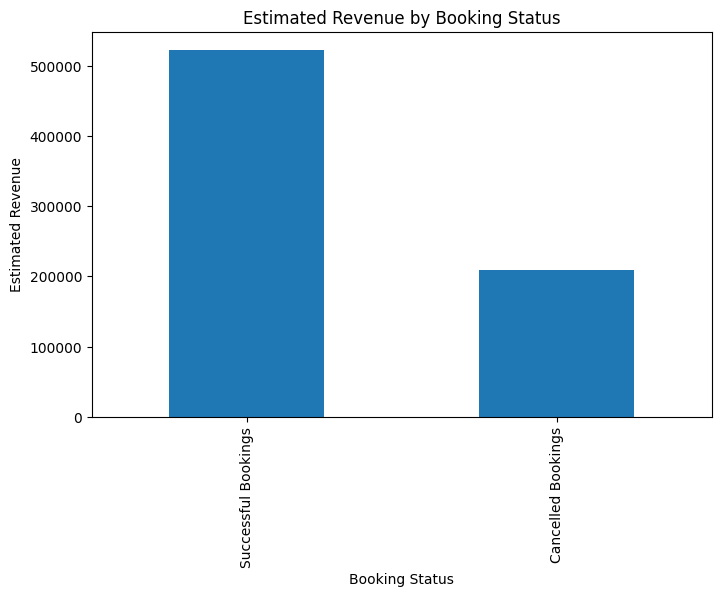

In [ ]:
df['estimated_revenue'] = df['adr'] * df['total_nights']

revenue = df.groupby('is_canceled')['estimated_revenue'].sum()

print("Revenue Analysis:")
print("Successful Booking Revenue:", revenue.get(0, 0))
print("Cancelled Booking Revenue:", revenue.get(1, 0))

plt.figure(figsize=(8,5))

revenue.rename({
    0: 'Successful Bookings',
    1: 'Cancelled Bookings'
}).plot(kind='bar')

plt.title("Estimated Revenue by Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Estimated Revenue")

plt.show()

In [ ]:
print("========== PROJECT CONCLUSION ==========")

print("1. Total bookings:", total_bookings)

print("2. Cancellation rate:",
      round(cancellation_rate, 2), "%")

print("3. Successful bookings:", successful_bookings)

print("4. Average stay:",
      round(df['total_nights'].mean(), 2), "nights")

print("5. Hotel booking analysis completed.")

print("\nRECOMMENDATIONS:")
print("1. Hotels should monitor booking cancellations.")
print("2. Hotels should improve customer communication.")
print("3. Hotels should plan staff according to monthly demand.")
print("4. Hotels should focus on customer satisfaction.")

========== PROJECT CONCLUSION ==========
1. Total bookings: 1200
2. Cancellation rate: 28.5 %
3. Successful bookings: 858
4. Average stay: 5.55 nights
5. Hotel booking analysis completed.

RECOMMENDATIONS:
1. Hotels should monitor booking cancellations.
2. Hotels should improve customer communication.
3. Hotels should plan staff according to monthly demand.
4. Hotels should focus on customer satisfaction.


In [ ]:
df.to_csv('HCL_Project_Final_Analysis.csv', index=False)

from google.colab import files

files.download('HCL_Project_Final_Analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>